In [1]:
import preprocessamento as pp
import treinamento as tr

import pandas as pd
pd.set_option('display.max_columns', None)
import yfinance as yf


In [2]:
from datetime import datetime, timedelta

In [3]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score
from sklearn.metrics import precision_recall_curve
from sklearn.linear_model import LogisticRegression
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
papel = 'BRAP4.SA'
papeis_adicionais = ['VALE3.SA']

In [5]:
# Parâmetros
DIAS_VALIDACAO = 90  # número de dias para simular produção

In [6]:
base = datetime.today().date() #- timedelta(days=1)
df_base = pp.montar_dataset(papel, dias_total_historico=750, data_base=base)
df_base = pp.buscar_dados_papeis_adicionais(df_base, papeis_adicionais)
df_base.tail(10)

[BRAP4.SA] Cache existente cobre de 2020-01-02 a 2025-07-31.
[BRAP4.SA] Cache cobre período solicitado (2022-07-02 a 2025-07-31).
[BRAP4.SA] Garantindo atualização dos últimos 5 dias do cache...
Index(['data', 'adj_close', 'close', 'Dividends', 'high', 'low', 'open',
       'Stock Splits', 'volume'],
      dtype='object', name='Price')
[BRAP4.SA] Últimos dias atualizados em memória com sucesso.
[BRAP4.SA] Retornando 769 linhas para o período solicitado.
✅ Usando cache local: /palpiteiro/dados\macro_20210702_20250801.csv
[^BVSP] Cache existente cobre de 2020-01-02 a 2025-07-31.
[^BVSP] Cache cobre período solicitado (2022-07-02 a 2025-07-31).
[^BVSP] Garantindo atualização dos últimos 5 dias do cache...
Index(['data', 'adj_close', 'close', 'Dividends', 'high', 'low', 'open',
       'Stock Splits', 'volume'],
      dtype='object', name='Price')
[^BVSP] Últimos dias atualizados em memória com sucesso.
[^BVSP] Retornando 769 linhas para o período solicitado.
[BOVA11.SA] Cache existente cob

,open,high,low,close,adj_close,volume,pct_change,vol,rsi,macd,macd_signal,macd_hist,ADX_14,DMP_14,DMN_14,BBL_20_2.0,BBM_20_2.0,BBU_20_2.0,BBB_20_2.0,BBP_20_2.0,atr_5,atr_50,obv,vwap,cmf,tr,atr,atr_pct,tr_pct,mm5,mm20,selic,ipca,dolar,open_ibov,high_ibov,low_ibov,close_ibov,adj_close_ibov,volume_ibov,adc_open_VALE3,adc_high_VALE3,adc_low_VALE3,adc_close_VALE3,adc_adj_close_VALE3,adc_volume_VALE3,adc_pct_change_VALE3,adc_vol_VALE3,adc_rsi_VALE3,adc_macd_VALE3,adc_macd_signal_VALE3,adc_macd_hist_VALE3,adc_ADX_14_VALE3,adc_DMP_14_VALE3,adc_DMN_14_VALE3,adc_BBL_20_2.0_VALE3,adc_BBM_20_2.0_VALE3,adc_BBU_20_2.0_VALE3,adc_BBB_20_2.0_VALE3,adc_BBP_20_2.0_VALE3,adc_atr_5_VALE3,adc_atr_50_VALE3,adc_obv_VALE3,adc_vwap_VALE3,adc_cmf_VALE3,adc_tr_VALE3,adc_atr_VALE3,adc_atr_pct_VALE3,adc_tr_pct_VALE3,adc_mm5_VALE3,adc_mm20_VALE3
data,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2025-07-18,16.000000,16.230000,15.990000,16.190001,16.190001,2404000,0.003720,0.013251,52.255098,0.097762,0.092466,0.005296,18.877931,26.525353,24.481234,15.051365,16.0255,16.999635,12.157309,0.584434,0.304237,0.344664,-36241000.0,16.136667,0.143065,0.240000,0.318517,0.019674,0.014824,16.192,16.0255,15.0,0.26,5.5466,135563.000000,135563.000000,133296.000000,133382.000,133382.000,6597946,54.049999,54.779999,53.970001,54.560001,54.560001,23714000,0.004788,0.014666,53.999969,0.472100,0.442020,0.030080,21.979954,28.289937,20.606762,50.418209,53.7405,57.062792,12.364200,0.623334,1.100326,1.164432,-381086100.0,54.436667,0.116553,0.809998,1.174671,0.021530,0.014846,54.506001,53.7405
2025-07-21,16.430000,16.790001,16.400000,16.580000,16.580000,3725400,0.024089,0.015169,59.770689,0.121198,0.098212,0.022986,19.252753,34.980790,21.382816,15.184880,16.0975,17.010120,11.338651,0.764349,0.363389,0.349771,-32515600.0,16.590000,0.084672,0.600000,0.338623,0.020424,0.036188,16.218,16.0975,15.0,0.26,5.5625,133382.000000,134865.000000,133367.000000,134167.000,134167.000,4533839,55.450001,56.820000,55.340000,56.049999,56.049999,40484000,0.027309,0.016261,61.026260,0.569559,0.467528,0.102031,22.824207,36.279620,17.950211,50.890437,54.0155,57.140563,11.570986,0.825513,1.332261,1.186343,-340602100.0,56.070000,0.073711,2.259998,1.252194,0.022341,0.040321,54.644000,54.0155
2025-07-22,16.730000,17.190001,16.670000,16.940001,16.940001,5224300,0.021713,0.016439,65.214017,0.166896,0.111949,0.054947,20.353217,38.704109,18.780410,15.307674,16.1860,17.064326,10.852906,0.929226,0.412712,0.354976,-27291300.0,16.933334,0.105993,0.610001,0.358007,0.021134,0.036009,16.394,16.1860,15.0,0.26,5.5709,134180.000000,135300.000000,133986.000000,134036.000,134036.000,4538075,56.950001,57.970001,56.910000,57.500000,57.500000,40945900,0.025870,0.017784,66.404245,0.755095,0.525041,0.230054,24.153156,38.771207,16.056407,51.314873,54.3635,57.412128,11.215715,1.014412,1.449809,1.201017,-299656200.0,57.460000,0.068402,1.920002,1.299895,0.022607,0.033391,55.362000,54.3635
2025-07-23,16.910000,17.040001,16.750000,16.980000,16.980000,3214600,0.002361,0.015566,65.768236,0.203988,0.130357,0.073632,21.375076,36.433881,17.678826,15.488596,16.2800,17.071404,9.722407,0.942252,0.388169,0.353676,-24076700.0,16.923333,0.121349,0.290001,0.353150,0.020798,0.017079,16.564,16.2800,15.0,0.26,5.5537,134036.000000,135782.000000,133676.000000,135368.000,135368.000,3129788,57.450001,57.900002,57.000000,57.419998,57.419998,17914800,-0.001391,0.017166,65.864221,0.885470,0.597127,0.288344,25.387180,36.810711,15.244502,51.941996,54.7105,57.479004,10.120559,0.989343,1.339848,1.194996,-317571000.0,57.440000,0.034326,0.900002,1.271331,0.022141,0.015674,55.966000,54.7105
2025-07-24,16.889999,16.920000,16.730000,16.770000,16.770000,2364500,-0.012367,0.014863,60.333380,0.213973,0.147080,0.066893,22.247127,34.552334,17.178994,15.625489,16.3460,17.066511,8.815748,0.794236,0.360536,0.351603,-26441200.0,16.806667,0.075411,0.250000,0.345782,0.020619,0.014908,16.692,16.3460,15.0,0.26,5.5239,135357.000000,135363.000000,133648.0000

<Axes: xlabel='data'>

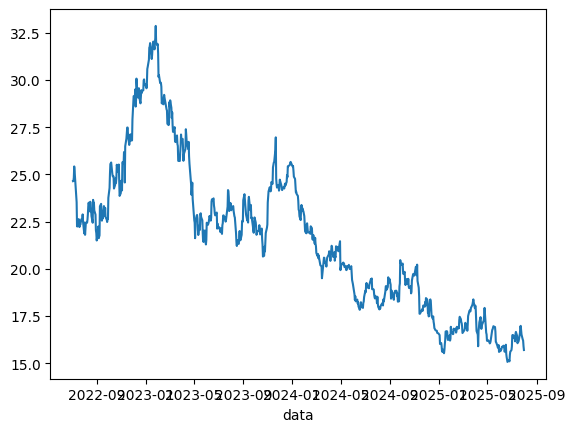

In [7]:
df_base['close'].plot()

## Verificação da volatilidade recente

In [8]:
df_base[['atr', 'atr_pct', 'tr', 'tr_pct']].tail(10)

,atr,atr_pct,tr,tr_pct
data,,,,
2025-07-18,0.318517,0.019674,0.240000,0.014824
2025-07-21,0.338623,0.020424,0.600000,0.036188
2025-07-22,0.358007,0.021134,0.610001,0.036009
2025-07-23,0.353150,0.020798,0.290001,0.017079
2025-07-24,0.345782,0.020619,0.250000,0.014908
2025-07-25,0.350369,0.021209,0.410000,0.024818
2025-07-28,0.352486,0.021678,0.380001,0.023370
2025-07-29,0.341594,0.021086,0.199999,0.012346
2025-07-30,0.347194,0.021836,0.420001,0.026415


In [9]:
ultimo_atr_pct = df_base['atr_pct'].iloc[-1]
multiplo_atr = 1.5
valorizacao_sugerida = ultimo_atr_pct * multiplo_atr
print(f'Último ATR %: {ultimo_atr_pct:.2%}')
print(f'Valorização sugerida: {valorizacao_sugerida:.2%}') 

Último ATR %: 2.25%
Valorização sugerida: 3.38%


## Re-preparação dos dados com valorização sugerida (calibrar dias_futuro de acordo com balanceamento da base)

In [10]:
valorizacao = 0.03
stop_loss = 0.01
DIAS_FUTURO = 3  # dias futuros para buscar a valorização

In [11]:
df = pp.calcular_target_com_stop(df_base, valorizacao_alvo_pct=valorizacao, dias_horizonte_alvo=DIAS_FUTURO, stop_loss_pct=stop_loss)
df['Target'].value_counts(normalize=True)

#0.0    0.789474
#1.0    0.210526

Target
0.0    0.789817
1.0    0.210183
Name: proportion, dtype: float64

In [45]:
# Preparar X e y para treino
DIAS_JANELA_X = 10  # janela de dados recentes que formam cada X
X, y = pp.preparar_X_y_agregado(df, DIAS_JANELA_X, dropna=True, tipo_drop_na='linhas')   

X_train, y_train, X_validacao, y_validacao = tr.dividir_treino_validacao(X, y, DIAS_VALIDACAO, dias_futuro=DIAS_FUTURO)

INFO: Papéis adicionais detectados para features: ['VALE3']


c:\Users\fsbertaggia\OneDrive - Secretaria da Fazenda e Planejamento do Estado de São Paulo\_Pessoal\Quant\palpiteiro\scripts\preprocessamento.py:893: RuntimeWarning: Mean of empty slice
  if lista_atr_pct_adicionais_ultimos: linha['adc_atr_pct_mean_geral_ultimo'] = np.nanmean(lista_atr_pct_adicionais_ultimos)
c:\Users\fsbertaggia\OneDrive - Secretaria da Fazenda e Planejamento do Estado de São Paulo\_Pessoal\Quant\palpiteiro\scripts\preprocessamento.py:893: RuntimeWarning: Mean of empty slice
  if lista_atr_pct_adicionais_ultimos: linha['adc_atr_pct_mean_geral_ultimo'] = np.nanmean(lista_atr_pct_adicionais_ultimos)
c:\Users\fsbertaggia\OneDrive - Secretaria da Fazenda e Planejamento do Estado de São Paulo\_Pessoal\Quant\palpiteiro\scripts\preprocessamento.py:893: RuntimeWarning: Mean of empty slice
  if lista_atr_pct_adicionais_ultimos: linha['adc_atr_pct_mean_geral_ultimo'] = np.nanmean(lista_atr_pct_adicionais_ultimos)
c:\Users\fsbertaggia\OneDrive - Secretaria da Fazenda e Planejam

In [46]:
X_train, removidas = tr.eliminar_features_correlacionadas(X_train, limite_correlacao=0.90, target=y_train)
X_validacao = X_validacao[X_train.columns]
print("Features removidas por alta correlação:", removidas)
print(f"Colunas restantes após filtragem: {X_train.shape[1]}")

Features removidas por alta correlação: ['adc_ret_acum_VALE3', 'macd_hist_ultimo_norm_atr_principal', 'macd_signal_ultimo', 'close_max', 'macd_ultimo', 'macd_ultimo_norm_atr_principal', 'tr_mean', 'close_mean', 'rsi_ultimo', 'close_amplitude_norm_atr_principal', 'tr_pct_mean', 'dias_alta_pct', 'adc_atr_pct_mean_geral_ultimo', 'macd_signal_mean', 'retorno_mean', 'bbands_posicao_pct_ultimo', 'adc_close_trend_VALE3', 'macd_signal_ultimo_norm_atr_principal', 'tr_pct_ultimo', 'close_std', 'dia_semana_4', 'tr_std', 'obv_mean', 'close_trend', 'adc_close_mean_geral_ultimo']
Colunas restantes após filtragem: 79


In [48]:
X_train.shape

(667, 79)

## teste de tamanho ideal do conj de treino

In [49]:
from sklearn.base import clone
from sklearn.model_selection import TimeSeriesSplit

def avaliar_estrategia_com_recall_em_precisao_minima(
        modelo_template,
        X_super_treino: pd.DataFrame,
        y_super_treino: pd.Series,
        n_splits: int = 5,
        tamanho_janela_treino: int = None, # Esta será a 'janela rolante'
        tamanho_janela_validacao: int = 30, # Adicionado para clareza
        precisao_minima_desejada: float = 0.60
    ):
    """
    Avalia uma estratégia de modelagem usando TimeSeriesSplit para simular uma janela
    de treino rolante, focando na métrica "Recall na Precisão Mínima".
    """
    print(f"\n--- Avaliando Estratégia com Recall na Precisão Mínima de {precisao_minima_desejada:.0%} ---")
    
    # O tamanho do conjunto de teste em TimeSeriesSplit é len(X) // (n_splits + 1)
    # Se você quer um tamanho de janela de validação fixo, o loop manual é mais explícito.
    # Mas vamos adaptar a lógica do TimeSeriesSplit para se aproximar do que você quer.
    # A maneira mais limpa de usar TimeSeriesSplit para este propósito é ajustar n_splits
    # de forma que o tamanho do teste seja próximo do que você deseja.
    if tamanho_janela_treino is None: # Comportamento original de janela expansível
        print(f"  Modo: Janela Expansível (n_splits={n_splits})")
        tscv = TimeSeriesSplit(n_splits=n_splits, test_size=tamanho_janela_validacao) # Define o tamanho do teste
    else: # Simular janela rolante
        print(f"  Modo: Janela Rolante (treino_max={tamanho_janela_treino}, teste={tamanho_janela_validacao}, n_splits={n_splits})")
        tscv = TimeSeriesSplit(
            n_splits=n_splits,
            max_train_size=tamanho_janela_treino,
            test_size=tamanho_janela_validacao # <<< Adicionado para fixar o tamanho da validação
        )
    
    recalls_na_precisao_minima = []

    for fold, (train_index, test_index) in enumerate(tscv.split(X_super_treino)):
        X_treino_fold = X_super_treino.iloc[train_index]
        y_treino_fold = y_super_treino.iloc[train_index] # <<< CORREÇÃO AQUI, antes estava test_index
        X_teste_fold = X_super_treino.iloc[test_index]
        y_teste_fold = y_super_treino.iloc[test_index]

        # Com test_size definido, a linha abaixo não é mais necessária, pois a janela já tem o tamanho certo
        # X_teste_fold = X_super_treino.iloc[test_index[:tamanho_janela_validacao]]
        # y_teste_fold = y_super_treino.iloc[test_index[:tamanho_janela_validacao]]

        print(f"Fold {fold + 1}/{n_splits}: Treinando com {len(X_treino_fold)} amostras, Validando com {len(X_teste_fold)}...")
        
        # <<< ADICIONADO: Pular o fold se não houver positivos no teste >>>
        # Isso evita que a métrica seja calculada em janelas onde não havia oportunidades
        if y_teste_fold.sum() == 0:
            print("  AVISO: Nenhum evento positivo na janela de teste. Recall será 0. Pulando para o próximo fold.")
            recalls_na_precisao_minima.append(0.0) # Adiciona 0 explicitamente
            continue

        modelo_fold = clone(modelo_template)
        try:
            modelo_fold.fit(X_treino_fold, y_treino_fold)
        except Exception as e:
            print(f"  ERRO no fit do Fold {fold + 1}: {e}. Pulando.")
            recalls_na_precisao_minima.append(0)
            continue
        
        probas_teste_fold = modelo_fold.predict_proba(X_teste_fold)[:, 1]

        # Supondo que tr.calcular_recall_em_precisao_minima é sua função auxiliar
        recall_neste_fold = tr.calcular_recall_em_precisao_minima(y_teste_fold, probas_teste_fold, precisao_minima_desejada)
        recalls_na_precisao_minima.append(recall_neste_fold)
        print(f"  Recall na Precisão >= {precisao_minima_desejada:.0%}: {recall_neste_fold:.3f}")

    if not recalls_na_precisao_minima:
        # ... (resto do seu código) ...
        return {'recall_medio_na_prec_min': 0, 'recall_std_na_prec_min': 0, 'prob_sucesso_folds': 0}

    recall_medio = np.mean(recalls_na_precisao_minima)
    recall_std = np.std(recalls_na_precisao_minima)
    prob_sucesso_folds = np.mean([1 if r > 0 else 0 for r in recalls_na_precisao_minima])

    print(f"\nResultado Final da Avaliação Walk-Forward:")
    print(f"  Recall Médio (com Precisão >= {precisao_minima_desejada:.0%}): {recall_medio:.3f}")
    print(f"  Desvio Padrão do Recall: {recall_std:.3f}")
    print(f"  Percentual de Folds com Sinal Viável: {prob_sucesso_folds:.0%}")

    resultado = {
        'recall_medio_na_prec_min': recall_medio,
        'recall_std_na_prec_min': recall_std,
        'prob_sucesso_folds': prob_sucesso_folds
    }
    return resultado




from sklearn.base import clone
# Supondo que tr.calcular_recall_em_precisao_minima é sua função auxiliar

def avaliar_estrategia_walk_forward_rolante(
        modelo_template,
        X_super_treino: pd.DataFrame,
        y_super_treino: pd.Series,
        tamanho_janela_treino: int, # Tamanho FIXO da janela de treino rolante
        tamanho_janela_validacao: int = 30, # Tamanho FIXO da janela de validação
        passo_wf: int = 30, # Quanto a janela desliza a cada iteração
        precisao_minima_desejada: float = 0.60
    ):
    """
    Avalia uma estratégia de modelagem usando um loop manual de walk-forward
    com JANELA DE TREINO ROLANTE para garantir que não haja gaps.

    Retorna métricas médias e desvio padrão para o screening.
    """
    print(f"\n--- Avaliando Estratégia com Walk-Forward Rolante (Treino={tamanho_janela_treino}, Val={tamanho_janela_validacao}, Passo={passo_wf}) ---")
    print(f"    (Métrica: Recall na Precisão Mínima de {precisao_minima_desejada:.0%})")

    if len(X_super_treino) < tamanho_janela_treino + tamanho_janela_validacao:
        print(f"AVISO: Dados de treino insuficientes ({len(X_super_treino)}) para a primeira janela completa.")
        return {'recall_medio_na_prec_min': 0, 'recall_std_na_prec_min': 0, 'prob_sucesso_folds': 0}

    recalls_na_precisao_minima = []
    n_total_amostras = len(X_super_treino)
    num_janelas_executadas = 0

    # O loop desliza o INÍCIO da janela de treino a cada 'passo_wf'
    for inicio_treino_idx in range(0, n_total_amostras, passo_wf):
        fim_treino_idx = inicio_treino_idx + tamanho_janela_treino
        
        # O teste começa IMEDIATAMENTE após o fim do treino
        inicio_validacao_idx = fim_treino_idx
        fim_validacao_idx = inicio_validacao_idx + tamanho_janela_validacao

        # Se a janela de validação ultrapassar o final dos dados, paramos o loop
        if fim_validacao_idx > n_total_amostras:
            break

        num_janelas_executadas += 1
        
        X_treino_fold = X_super_treino.iloc[inicio_treino_idx : fim_treino_idx]
        y_treino_fold = y_super_treino.iloc[inicio_treino_idx : fim_treino_idx]
        X_teste_fold = X_super_treino.iloc[inicio_validacao_idx : fim_validacao_idx]
        y_teste_fold = y_super_treino.iloc[inicio_validacao_idx : fim_validacao_idx]

        print(f"Fold {num_janelas_executadas}: Treinando de {X_treino_fold.index.min()} a {X_treino_fold.index.max()} ({len(X_treino_fold)} amostras). "
              f"Validando de {X_teste_fold.index.min()} a {X_teste_fold.index.max()} ({len(X_teste_fold)} amostras).")

        if y_teste_fold.sum() == 0:
            print("  AVISO: Nenhum evento positivo na janela de teste. Recall será 0.")
            recalls_na_precisao_minima.append(0.0)
            continue

        modelo_fold = clone(modelo_template)
        try:
            modelo_fold.fit(X_treino_fold, y_treino_fold)
        except Exception as e:
            print(f"  ERRO no fit do Fold {num_janelas_executadas}: {e}. Pulando.")
            recalls_na_precisao_minima.append(0)
            continue
        
        probas_teste_fold = modelo_fold.predict_proba(X_teste_fold)[:, 1]

        recall_neste_fold = tr.calcular_recall_em_precisao_minima(y_teste_fold, probas_teste_fold, precisao_minima_desejada)
        recalls_na_precisao_minima.append(recall_neste_fold)
        print(f"  Recall na Precisão >= {precisao_minima_desejada:.0%}: {recall_neste_fold:.3f}")

    if not recalls_na_precisao_minima:
        print("AVISO: Nenhuma janela de walk-forward foi processada com sucesso.")
        return {'recall_medio_na_prec_min': 0, 'recall_std_na_prec_min': 0, 'prob_sucesso_folds': 0}

    recall_medio = np.mean(recalls_na_precisao_minima)
    recall_std = np.std(recalls_na_precisao_minima)
    prob_sucesso_folds = np.mean([1 if r > 0 else 0 for r in recalls_na_precisao_minima])

    print(f"\nResultado Final da Avaliação ({num_janelas_executadas} folds):")
    print(f"  Recall Médio (com Precisão >= {precisao_minima_desejada:.0%}): {recall_medio:.3f}")
    print(f"  Desvio Padrão do Recall: {recall_std:.3f}")
    print(f"  Percentual de Folds com Sinal Viável: {prob_sucesso_folds:.0%}")

    resultado = {
        'recall_medio_na_prec_min': recall_medio,
        'recall_std_na_prec_min': recall_std,
        'prob_sucesso_folds': prob_sucesso_folds
    }
    return resultado

In [59]:
modelo_template = LogisticRegression(solver='liblinear', penalty='l1', random_state=42, class_weight='balanced', C=0.0001)
        
precisao_minima = 0.4
tamanho_janela_treino_passo1 = 250
metricas_passo1 = avaliar_estrategia_walk_forward_rolante(
    modelo_template=modelo_template,
    X_super_treino=X_train,
    y_super_treino=y_train,
    tamanho_janela_treino=tamanho_janela_treino_passo1,
    tamanho_janela_validacao=30, # Fixo
    passo_wf=30, # Desliza pela janela de validação
    precisao_minima_desejada=0.50
)
print(metricas_passo1)


--- Avaliando Estratégia com Walk-Forward Rolante (Treino=250, Val=30, Passo=30) ---
    (Métrica: Recall na Precisão Mínima de 50%)
Fold 1: Treinando de 2022-07-15 a 2023-07-14 (250 amostras). Validando de 2023-07-17 a 2023-08-25 (30 amostras).
  ERRO no fit do Fold 1: Input X contains NaN.
LogisticRegression does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values. Pulando.
Fold 2: Treinando de 2022-08-26 a 2023-08-25 (250 amostras). Validando de 202

In [60]:
# Passo 2: Teste Incrementalmente o Tamanho da Janela de Treino
tamanhos_de_janela_para_testar = [120, 180, 250, 375, 500]
resultados_por_janela = []
for tamanho in tamanhos_de_janela_para_testar:
    metricas = avaliar_estrategia_walk_forward_rolante(
        modelo_template=modelo_template,
        X_super_treino=X_train,
        y_super_treino=y_train,
        tamanho_janela_treino=tamanho,
        tamanho_janela_validacao=30,
        passo_wf=30,
        precisao_minima_desejada=0.40
    )
    metricas['tamanho_janela_treino'] = tamanho
    resultados_por_janela.append(metricas)
df_resultados_janelas = pd.DataFrame(resultados_por_janela)


--- Avaliando Estratégia com Walk-Forward Rolante (Treino=120, Val=30, Passo=30) ---
    (Métrica: Recall na Precisão Mínima de 40%)
Fold 1: Treinando de 2022-07-15 a 2023-01-05 (120 amostras). Validando de 2023-01-06 a 2023-02-16 (30 amostras).
  ERRO no fit do Fold 1: Input X contains NaN.
LogisticRegression does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values. Pulando.
Fold 2: Treinando de 2022-08-26 a 2023-02-16 (120 amostras). Validando de 202

In [61]:
df_resultados_janelas.sort_values(by='recall_medio_na_prec_min', ascending=False)

,recall_medio_na_prec_min,recall_std_na_prec_min,prob_sucesso_folds,tamanho_janela_treino
0,0.307071,0.349117,0.500000,120
2,0.283974,0.350007,0.538462,250
1,0.199621,0.286043,0.375000,180
3,0.125926,0.259999,0.222222,375
4,0.066667,0.133333,0.200000,500


## Prosseguimos com o tamanho do X selecionado

In [26]:
tamanho_X = 180
X_train = X_train.iloc[-tamanho_X:]
y_train = y_train.iloc[-tamanho_X:]
X_train.shape, y_train.shape

((180, 77), (180,))

In [27]:
X_train, removidas = tr.eliminar_features_correlacionadas(X_train, limite_correlacao=0.95, target=y_train)
X_validacao = X_validacao[X_train.columns]
print("Features removidas por alta correlação:", removidas)
print(f"Colunas restantes após filtragem: {X_train.shape[1]}")

Features removidas por alta correlação: []
Colunas restantes após filtragem: 77


In [28]:
X_train.tail()

,close_max,close_trend,retorno_desde_mudanca_close,close_amplitude,close_dist_min,close_ult_vs_mm_janela,mm5_vs_mm20,retorno_mean,dias_queda_pct,retorno_medio_pos,retorno_medio_neg,volume_mean,volume_std,volume_trend,volume_ult_vs_mean,atr_pct_ultimo,rsi_mean,rsi_std,rsi_ultimo,macd_std,macd_signal_mean,macd_signal_std,macd_hist_mean,macd_hist_std,tr_mean,tr_std,obv_mean,obv_std,obv_ultimo,obv_trend,cmf_mean,cmf_std,cmf_ultimo,cmf_trend,close_vs_vwap,correl_retorno_volume,relacao_vol_alta_queda,retorno_ponderado_vol_mean,pico_volume_recente_2x,adx_ultimo,adx_mean,adx_trend,tendencia_forte_adx25,tendencia_positiva_dominante,bbands_largura_pct_ultimo,bbands_largura_pct_mean,bbands_largura_pct_trend,bbands_posicao_pct_ultimo,bbands_exaustao_compra,bbands_exaustao_venda,regime_vol_atr_curto_longo,adc_adx_ultimo_VALE3,adc_adx_trend_VALE3,adc_tendencia_positiva_dominante_VALE3,adc_bbands_largura_pct_ultimo_VALE3,adc_bbands_posicao_pct_ultimo_VALE3,adc_correl_com_principal_VALE3,adc_close_mean_geral_ultimo,close_vs_adc_close_mean_geral,adc_atr_pct_mean_geral_ultimo,adc_ret_acum_mean_geral_janela,atr_ultimo,macd_hist_ultimo_norm_atr_principal,tr_ultimo_norm_atr_principal,rsi_sobrecomprado_70,rsi_sobrevendido_30,adc_bbands_exaustao_compra_VALE3,adc_bbands_exaustao_venda_VALE3,adc_tendencia_forte_adx25_VALE3,macd_acima_sinal,macd_cruzou_sinal_para_cima,dia_semana_0,dia_semana_1,dia_semana_2,dia_semana_3,dia_semana_4,feriado
2025-03-12,17.170000,-0.023273,0.000000,0.570000,0.119999,-0.194001,-0.002125,-0.003505,0.6,0.009686,-0.012299,2825940.0,1.082217e+06,66976.969697,-0.323800,0.021167,51.238955,4.355677,46.892749,0.045924,0.098737,0.014160,-0.002662,0.037766,0.363,0.126496,-52032910.0,3.204149e+06,-51235900.0,3.569836e+05,0.028010,0.045639,0.079642,0.010543,-0.002387,0.114732,1.201302,-8490.690448,0,14.138983,15.650386,-0.469969,0,1,5.469734,5.864832,-0.125538,0.258305,0,0,0.044847,15.662570,-0.571569,0,8.663816,0.067572,0.817327,53.759998,-0.688988,0.024175,-0.057999,0.353919,-0.097082,1.045434,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,1,0,0,0
2025-03-13,17.139999,0.000121,0.000000,0.539999,0.430000,0.130000,-0.000560,-0.000727,0.5,0.011457,-0.012912,2852180.0,1.057321e+06,-43745.454545,-0.278867,0.021395,50.796431,3.841492,53.091133,0.040507,0.095784,0.017005,-0.011811,0.028242,0.392,0.120628,-51960270.0,3.265387e+06,-49179100.0,6.544733e+05,0.029622,0.046229,0.051990,0.012375,0.003536,-0.069954,1.052268,-3020.542170,0,14.651924,15.350073,-0.390787,0,1,5.453351,5.744013,-0.094868,0.582745,0,0,0.102342,14.821987,-0.583878,0,8.863406,0.233300,0.832249,54.500000,-0.687523,0.024057,-0.039140,0.364353,-0.060552,1.372294,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,1,0,0
2025-03-14,17.500000,0.047515,0.027598,0.900000,0.900000,0.562000,0.001088,0.002324,0.4,0.014147,-0.015412,3063800.0,9.973345e+05,-75513.939394,0.225276,0.021741,51.237444,4.689052,60.599488,0.029737,0.091940,0.017406,-0.015375,0.020514,0.426,0.124025,-51348450.0,3.869483e+06,-45425100.0,1.038735e+06,0.041987,0.056720,0.136936,0.017139,0.005362,0.046455,0.999361,7816.794297,0,16.215937,15.164640,-0.162211,0,1,5.805455,5.716048,-0.068777,1.009231,1,0,0.189138,14.501561,-0.524595,1,8.712870,0.581211,0.874679,56.290001,-0.689110,0.024052,-0.000178,0.380471,0.042492,1.550710,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0,0,0,0,1,0
2025-03-17,17.750000,0.092606,0.042278,1.150000,1.150000,0.732000,0.008446,0.004745,0.3,0.014167,-0.017239,2955380.0,9.622929e+05,-40967.272727,-0.068648,0.021554,52.447088,6.177756,63.908667,0.028999,0.088806,0.014821,-0.012535,0.027634,0.418,0.122002,-50077710.0,4.442538e+06,-42672600.0,1.243193e+06,0.057205,0.054875,0.119596,0.016401,0.004717,0.107317,1.075122,15558.745920,0,18.086958,15.250112,0.135028,0,1,6.717628,5.778839,0.010765,1.111164,1,0,0.169760,14.775356,-0.410287,1,8.714806,0.724038,0.886954,57.099998,-0.689142,0.023393,0.035358,0.382580,0.142636,1.071670,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1,0,0,0,0,0
2025-03-18,17.799999,0.107394,0.045214,1.080000,1.080000,0.661999,0.015591,0.0

# LogisticRegression

# otimização de parametris

In [29]:
def recall_at_min_precision_scorer(y_true, y_probas, min_precision=0.50):
    """
    Função de scoring customizada e robusta para GridSearchCV.
    Calcula o maior recall possível para uma precisão mínima desejada.
    Projetada para nunca retornar NaN.
    """
    try:
        # Condições de borda que podem levar a resultados inválidos
        if np.sum(y_true) == 0: # Nenhum positivo real no fold de teste
            return 0.0
        if len(np.unique(y_probas)) == 1: # Modelo prevê a mesma probabilidade para todos
            return 0.0

        precisions, recalls, thresholds = precision_recall_curve(y_true, y_probas)

        # A curva retorna um valor a mais para P e R. Excluímos o ponto final (P=1, R=0).
        precisions = precisions[:-1]
        recalls = recalls[:-1]

        # Se, após a exclusão, os arrays estiverem vazios, não há o que fazer.
        if len(precisions) == 0:
            return 0.0

        # Encontrar os índices onde a precisão é >= à mínima desejada
        indices_validos = np.where(precisions >= min_precision)[0]

        if len(indices_validos) == 0:
            # Se nenhum ponto na curva atinge a precisão mínima
            return 0.0
        else:
            # Dentre os pontos que atendem à precisão, retornamos o que tem o maior recall.
            melhor_recall = np.max(recalls[indices_validos])
            return float(melhor_recall) # Garante que o tipo é um float padrão

    except Exception as e:
        # Captura qualquer outro erro inesperado e retorna 0 em vez de falhar/retornar NaN
        # print(f"AVISO: Exceção na função de scoring: {e}. Retornando score 0.") # Opcional para depuração
        return 0.0

In [30]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import make_scorer, average_precision_score, f1_score # PR AUC é bom para desbalanceados

def otimizar_hiperparametros_logreg(X_super_treino, y_super_treino, n_splits_cv=5,precisao_minima_para_otimizacao=0.50):
    """
    Encontra os melhores hiperparâmetros para a Regressão Logística usando
    GridSearchCV com TimeSeriesSplit.

    Args:
        X_super_treino: Seu DataFrame de "super treino" (ex: os 510 dias).
        y_super_treino: Seus alvos correspondentes.
        n_splits_cv (int): Número de folds para a validação cruzada temporal.

    Returns:
        O melhor modelo treinado encontrado pelo GridSearchCV.
    """
    print(f"\n--- Iniciando Otimização de Hiperparâmetros com TimeSeriesSplit (n_splits={n_splits_cv}) ---")
    
    # 1. Definir o splitter de validação cruzada para séries temporais
    tscv = TimeSeriesSplit(n_splits=n_splits_cv)

    # 2. Definir o modelo base (não treinado)
    # Aumentar max_iter para garantir que solvers como 'saga' e 'lbfgs' convirjam.
    class_weight = 'balanced'
    log_reg_template = LogisticRegression(random_state=42, max_iter=10000, class_weight=class_weight)

    # 3. Definir o "grid" de parâmetros a serem testados
    param_grid = [
        {
            'penalty': ['l1'], # Penalidade Lasso (seleção de features)
            'solver': ['liblinear', 'saga'],
            'C': np.logspace(-4, 2, 8) # Isso testa: [0.0001, 0.001, 0.01, 0.1, 1.0, 10.0, 100.0]                                        
        },
        {
            'penalty': ['l2'], # Penalidade Ridge (encolhimento de features)
            'solver': ['liblinear', 'lbfgs', 'saga'],
            'C': np.logspace(-4, 2, 8) # Isso testa: [0.0001, 0.001, 0.01, 0.1, 1.0, 10.0, 100.0]                                        
        }
    ]

    # 4. Definir a métrica de scoring
    # 'roc_auc' é bom, mas 'average_precision' (PR AUC) é muitas vezes melhor para
    # dados desbalanceados e quando a precisão na classe positiva é importante.
    #scorer = make_scorer(average_precision_score)
    scorer = make_scorer(f1_score)

    #custom_scorer = make_scorer(
    #    recall_at_min_precision_scorer,
    ###    needs_proba=True,
    #    greater_is_better=True, # Queremos maximizar este score
    #    min_precision=precisao_minima_para_otimizacao # Passa o parâmetro para a nossa função
    #)

    # 5. Configurar e executar o GridSearchCV
    grid_search = GridSearchCV(
        estimator=log_reg_template,
        param_grid=param_grid,
        scoring=scorer,
        cv=tscv, # Usar o splitter temporal
        n_jobs=-1, # Usar todos os cores da CPU
        verbose=1  # Mostrar progresso
    )

    grid_search.fit(X_super_treino, y_super_treino)

    print("\n--- Resultados da Otimização ---")
    print(f"Melhor Score ({scorer}): {grid_search.best_score_:.4f}")
    print("Melhores Parâmetros Encontrados:")
    print(grid_search.best_params_)

    # O grid_search.best_estimator_ já é o modelo treinado com os melhores parâmetros
    # em todo o X_super_treino.
    return grid_search.best_estimator_

In [31]:
print("Verificando X_super_treino por NaNs ou Infinitos:")
print(X_train.isnull().sum().sum()) # Total de NaNs
print(np.isinf(X_train).sum().sum()) # Total de Infinitos

print("\nVerificando y_super_treino por NaNs:")
print(X_train.isnull().sum())

Verificando X_super_treino por NaNs ou Infinitos:
0
0

Verificando y_super_treino por NaNs:
close_max                      0
close_trend                    0
retorno_desde_mudanca_close    0
close_amplitude                0
close_dist_min                 0
                              ..
dia_semana_1                   0
dia_semana_2                   0
dia_semana_3                   0
dia_semana_4                   0
feriado                        0
Length: 77, dtype: int64


In [32]:
modelo_otimizado = otimizar_hiperparametros_logreg(X_train, y_train, n_splits_cv=5, precisao_minima_para_otimizacao=0.2)
modelo_otimizado


--- Iniciando Otimização de Hiperparâmetros com TimeSeriesSplit (n_splits=5) ---
Fitting 5 folds for each of 40 candidates, totalling 200 fits

--- Resultados da Otimização ---
Melhor Score (make_scorer(f1_score, response_method='predict')): 0.2086
Melhores Parâmetros Encontrados:
{'C': np.float64(0.03727593720314938), 'penalty': 'l2', 'solver': 'lbfgs'}


LogisticRegression(C=np.float64(0.03727593720314938), class_weight='balanced',
                   max_iter=10000, random_state=42)

AUC no treino: 0.762
AUC na validação: 0.456
Diferença AUC (Treino - Validação): 0.306
PROVÁVEL OVERFITTING
PR AUC no treino: 0.495
PR AUC na validação: 0.241
Diferença PR AUC (Treino - Validação): 0.255
F1 Score no treino: 0.411
F1 Score na validação: 0.117


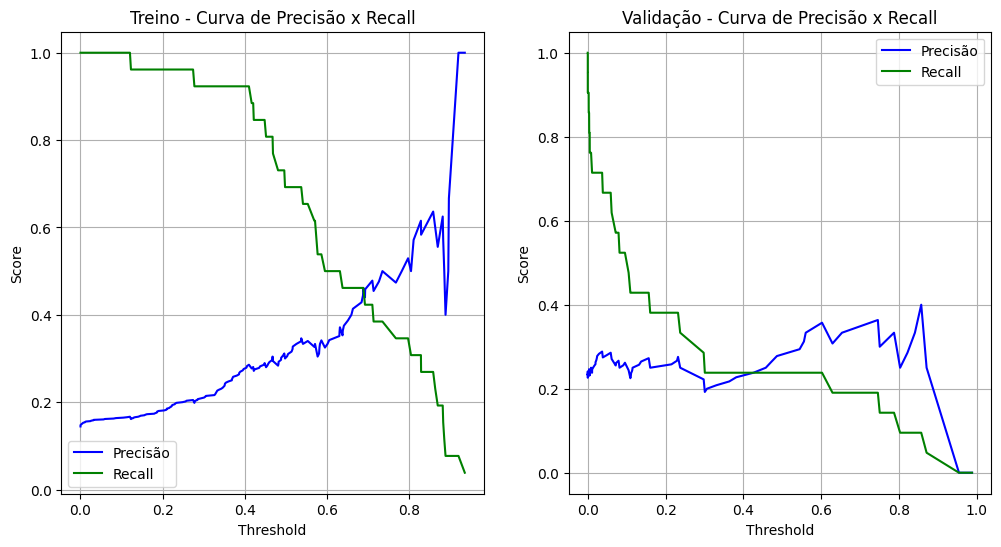

(np.float64(0.7615075651368454),
 np.float64(0.4556435451891434),
 np.float64(0.30586401994770196),
 np.float64(0.495226586221133),
 np.float64(0.24069685567236013),
 np.float64(0.4113626497864618),
 np.float64(0.11734716502579043))

In [33]:
modelo_otimizado.fit(X_train, y_train)
tr.comparar_auc_conjuntos(modelo_otimizado, X_train, y_train, X_validacao, y_validacao)

In [34]:
df_coef = pd.DataFrame({
    'coef_abs': np.abs(modelo_otimizado.coef_[0]),
    'coef': modelo_otimizado.coef_[0],
    'feature': X_train.columns
})
df_coef[df_coef['coef_abs'] > 0]['feature'].values

array(['close_max', 'close_trend', 'retorno_desde_mudanca_close',
       'close_amplitude', 'close_dist_min', 'close_ult_vs_mm_janela',
       'mm5_vs_mm20', 'retorno_mean', 'dias_queda_pct',
       'retorno_medio_pos', 'retorno_medio_neg', 'volume_mean',
       'volume_std', 'volume_trend', 'volume_ult_vs_mean',
       'atr_pct_ultimo', 'rsi_mean', 'rsi_std', 'rsi_ultimo', 'macd_std',
       'macd_signal_mean', 'macd_signal_std', 'macd_hist_mean',
       'macd_hist_std', 'tr_mean', 'tr_std', 'obv_mean', 'obv_std',
       'obv_ultimo', 'obv_trend', 'cmf_mean', 'cmf_std', 'cmf_ultimo',
       'cmf_trend', 'close_vs_vwap', 'correl_retorno_volume',
       'relacao_vol_alta_queda', 'retorno_ponderado_vol_mean',
       'pico_volume_recente_2x', 'adx_ultimo', 'adx_mean', 'adx_trend',
       'tendencia_forte_adx25', 'tendencia_positiva_dominante',
       'bbands_largura_pct_ultimo', 'bbands_largura_pct_mean',
       'bbands_largura_pct_trend', 'bbands_posicao_pct_ultimo',
       'bbands_exaus

In [35]:
df_coef.sort_values(by='coef_abs', ascending=False).head(20)

,coef_abs,coef,feature
51,0.090218,0.090218,adc_adx_ultimo_VALE3
16,0.047486,-0.047486,rsi_mean
44,0.029521,-0.029521,bbands_largura_pct_ultimo
18,0.017882,-0.017882,rsi_ultimo
39,0.016276,0.016276,adx_ultimo
54,0.013331,0.013331,adc_bbands_largura_pct_ultimo_VALE3
57,0.012263,0.012263,adc_close_mean_geral_ultimo
0,0.009612,0.009612,close_max
46,0.008311,-0.008311,bbands_largura_pct_trend
68,0.007464,0.007464,adc_tendencia_forte_adx25_VALE3


Avaliar e logar modelo
MLflow Tracking URI definido para: file:///C:/palpiteiro/mlruns
Experimento 'Modelo_B3' já existe (ID: 378581376299543397).
  Artifact Location existente: file:///C:/palpiteiro/mlruns/378581376299543397
MLflow Run ID: 3f6f46bfa0ff432f87424bb9a7170abb para BRAP4.SA_10dias_x_0.03val_3dias_alvo
AUC no treino: 0.804
AUC na validação: 0.542

--- Conjunto de Treino --- Janelas

Threshold 0.50 - AUC: 0.762
  Precisão média (em 151 janelas com previsão positiva): 0.298
  Recall médio: 0.693

Calibrando thresholds para precisão mínima de 0.55...

Threshold Ideal Selecionado: 0.81
  Precisão Média Esperada: 58.52%
  Recall Médio Esperado: 30.55%
  Janelas Usadas para Precisão: 124.0

Threshold ideal baseado em mínimo recall ou precisão: 0.81

--- Conjunto de Validação --- Janelas
Precisão média (em 35 janelas com previsão positiva): 0.212
Recall médio: 0.133
Sinais de compra presentes na vallidação: 21.0
Sinais de compra previstos na validação: 7


c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\mlflow\types\utils.py:452: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


Modelo BRAP4.SA_10dias_x_0.03val_3dias_alvo salvo na run 3f6f46bfa0ff432f87424bb9a7170abb


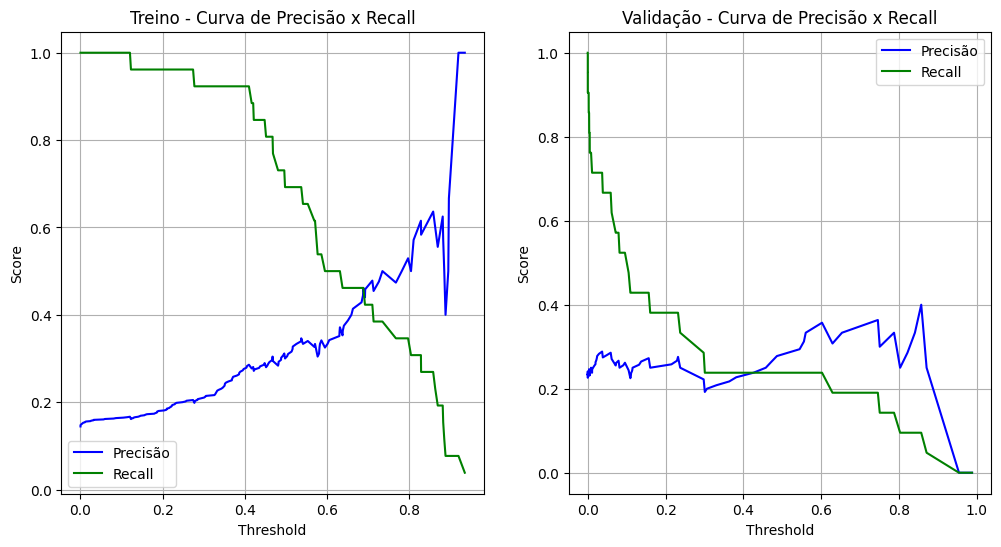

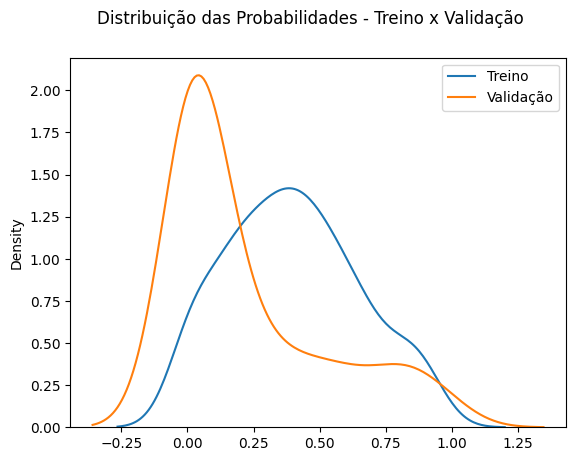

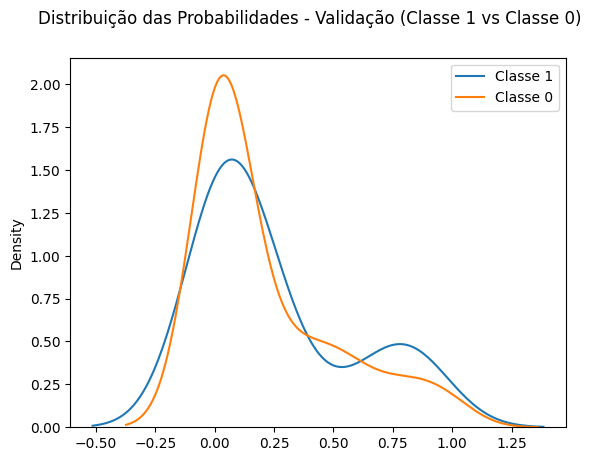

In [40]:
recall_minimo = None
precisao_minima = 0.55
resultado = tr.avaliar_e_logar_modelo(modelo_otimizado, papel, X_train, y_train, X_validacao, y_validacao, dias_janela_x=DIAS_JANELA_X, valorizacao=valorizacao, stop_loss=stop_loss,dias_futuro_valorizacao=DIAS_FUTURO,dias_validacao=DIAS_VALIDACAO, recall_minimo=recall_minimo, precisao_minima=precisao_minima)
threshold_calibrado = resultado['threshold_calibrado']
probas = resultado['probas_validacao']
y_true = resultado['y_validacao']
y_pred = resultado['y_pred_validacao']

# Redução de features

In [108]:
# Importâncias
importancias = pd.Series(modelo_rl.coef_[0], index=X_train.columns)
df_importancias = pd.DataFrame({
    'Feature': importancias.index,
    'importancia': importancias.values,
    'importancia_abs': importancias.abs().values
})
df_importancias.sort_values(by='importancia_abs', ascending=False, inplace=True)
df_importancias.head(15)


,Feature,importancia,importancia_abs
34,adc_rsi_ultimo_VALE3,-0.049238,0.049238
1,close_min,0.017402,0.017402
59,close_amplitude_norm_atr_principal,-0.015766,0.015766
61,dia_semana,0.014178,0.014178
45,ipca_dias_desde_mudanca,0.013987,0.013987
20,rsi_mean,0.010755,0.010755
0,close_max,0.010339,0.010339
21,rsi_std,-0.010200,0.010200
37,adc_close_mean_geral_ultimo,0.009812,0.009812
41,selic_comparacao_anterior,0.007647,0.007647



--- Iniciando Avaliação Robusta de k=[5, 10, 15, 20, 25, 30, 35, 40] com Walk-Forward ---
  Resultado Médio para k=5: F1=0.165, Precisão=0.143
  Resultado Médio para k=10: F1=0.186, Precisão=0.150
  Resultado Médio para k=15: F1=0.191, Precisão=0.156
  Resultado Médio para k=20: F1=0.202, Precisão=0.189
  Resultado Médio para k=25: F1=0.202, Precisão=0.189
  Resultado Médio para k=30: F1=0.183, Precisão=0.211
  Resultado Médio para k=35: F1=0.183, Precisão=0.211
  Resultado Médio para k=40: F1=0.183, Precisão=0.211


,k_features,f1_medio,precisao_media,recall_medio,recall_na_precisao_minima,f1_std
0,5,0.164815,0.143387,0.366667,0.166667,0.200864
1,10,0.186147,0.150112,0.400000,0.166667,0.239694
2,15,0.191292,0.155952,0.400000,0.166667,0.247375
3,20,0.202403,0.189286,0.366667,0.200000,0.263462
4,25,0.201662,0.188889,0.366667,0.200000,0.263843
5,30,0.183333,0.211111,0.166667,0.166667,0.260875
6,35,0.183333,0.211111,0.166667,0.166667,0.260875
7,40,0.183333,0.211111,0.166667,0.166667,0.260875


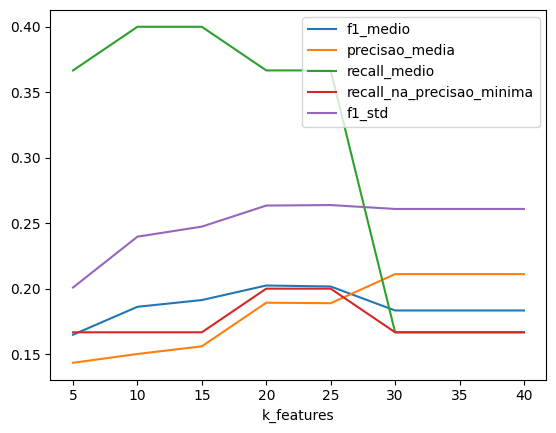

In [118]:
modelo_template_logreg = LogisticRegression(solver='liblinear', random_state=42, class_weight='balanced', penalty='l2', C=0.01) # Exemplo

# 2. Defina os valores de k que você quer testar
k_values_para_teste = list(range(5, 41, 5)) # Ex: [5, 10, 15, 20, 25, 30]

tr.avaliar_k_features_com_walk_forward(
    X_super_treino=X_train,
    y_super_treino=y_train,
    k_values=k_values_para_teste,
    modelo_template=modelo_template_logreg,
    tamanho_janela_treino_wf=60, # Seus parâmetros de janela
    tamanho_janela_validacao_wf=30,
    passo_wf=30,
    precisao_minima_desejada=0.6
)

# Features reduzidas

In [119]:
n_features = 20
lista_colunas_selecionadas = df_importancias.head(n_features)['Feature'].tolist()
lista_colunas_selecionadas

['adc_rsi_ultimo_VALE3',
 'close_min',
 'close_amplitude_norm_atr_principal',
 'dia_semana',
 'ipca_dias_desde_mudanca',
 'rsi_mean',
 'close_max',
 'rsi_std',
 'adc_close_mean_geral_ultimo',
 'selic_comparacao_anterior',
 'close_amplitude',
 'rsi_ultimo',
 'selic_ultimo',
 'dolar_ultimo',
 'adc_correl_com_principal_VALE3',
 'close_dist_min',
 'correl_papel_ibov',
 'beta_papel_ibov',
 'proximo_dia_util',
 'ipca_comparacao_anterior']

In [111]:
X_train_reduzido = X_train[lista_colunas_selecionadas].copy()
X_validacao_reduzido = X_validacao[lista_colunas_selecionadas].copy()

In [120]:
modelo_rl_reduzido = LogisticRegression(solver='liblinear', random_state=42, penalty='l2',class_weight='balanced', C=0.01)
modelo_rl_reduzido.fit(X_train_reduzido, y_train)
tr.comparar_auc_conjuntos(modelo_rl_reduzido, X_train_reduzido, y_train, X_validacao_reduzido, y_validacao)

AUC no treino: 0.714
AUC na validação: 0.553
Diferença AUC (Treino - Validação): 0.161
PROVÁVEL OVERFITTING
PR AUC no treino: 0.425
PR AUC na validação: 0.368
Diferença PR AUC (Treino - Validação): 0.057
F1 Score no treino: 0.367
F1 Score na validação: 0.216


(np.float64(0.7144848269018561),
 np.float64(0.5530435092388175),
 np.float64(0.1614413176630386),
 np.float64(0.4245112912143728),
 np.float64(0.36785507403163337),
 np.float64(0.3674943775628131),
 np.float64(0.21619081657042108))

Avaliar e logar modelo
MLflow Tracking URI definido para: file:///C:/palpiteiro/mlruns
Experimento 'Modelo_B3' já existe (ID: 378581376299543397).
  Artifact Location existente: file:///C:/palpiteiro/mlruns/378581376299543397
MLflow Run ID: eba36e824fa0412f8a2dd50e7c04f1ee para BRAP4.SA_10dias_x_0.03val_3dias_alvo
AUC no treino: 0.705
AUC na validação: 0.577

--- Conjunto de Treino --- Janelas

Threshold 0.50 - AUC: 0.714
  Precisão média (em 221 janelas com previsão positiva): 0.262
  Recall médio: 0.640

Calibrando thresholds para precisão mínima de 0.55...

Threshold Ideal Selecionado: 0.66
  Precisão Média Esperada: 65.49%
  Recall Médio Esperado: 26.95%
  Janelas Usadas para Precisão: 121.0

Threshold ideal baseado em mínimo recall ou precisão: 0.66

--- Conjunto de Validação --- Janelas
Precisão média (em 13 janelas com previsão positiva): 0.035
Recall médio: 0.006
Sinais de compra presentes na vallidação: 23.0
Sinais de compra previstos na validação: 7


c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\mlflow\types\utils.py:452: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


Modelo BRAP4.SA_10dias_x_0.03val_3dias_alvo salvo na run eba36e824fa0412f8a2dd50e7c04f1ee


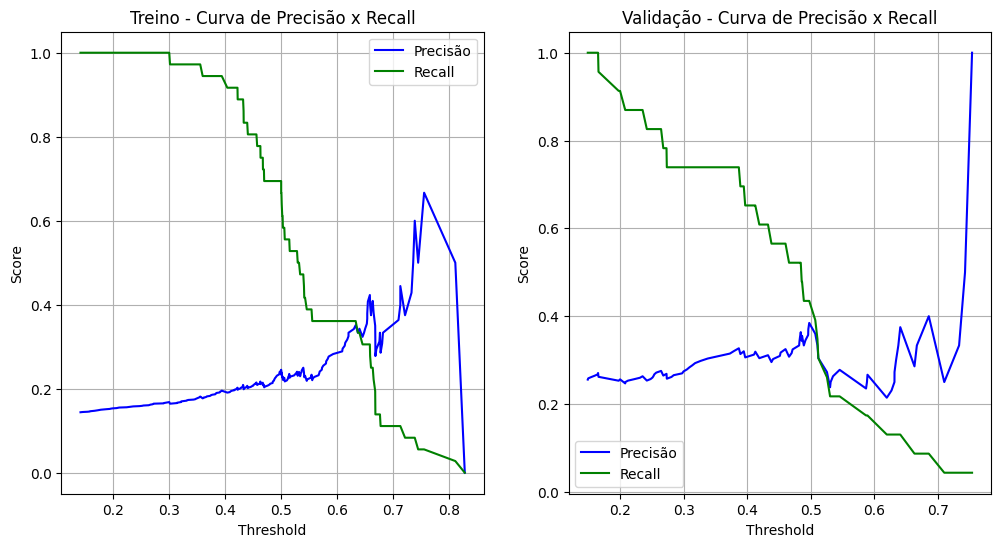

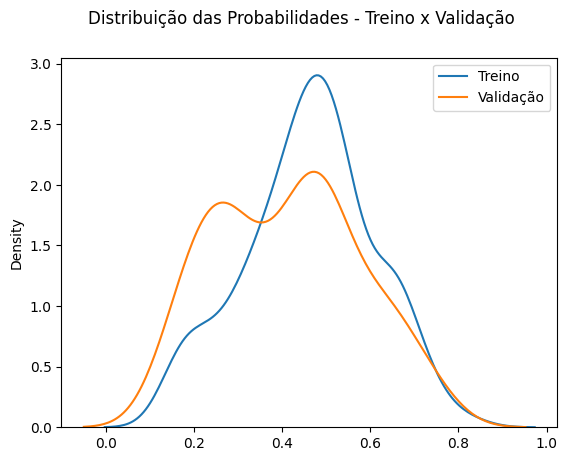

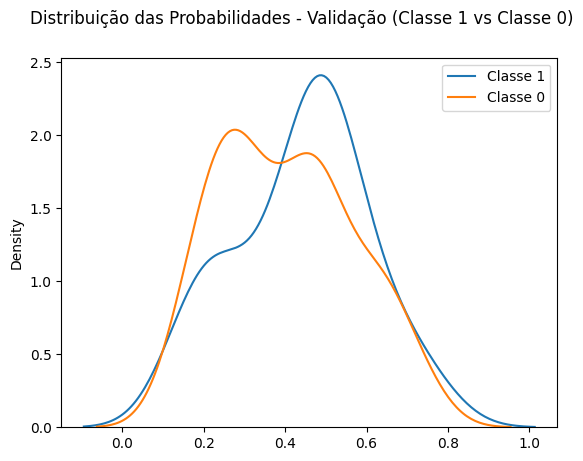

In [121]:
recall_minimo = None
precisao_minima = 0.55
resultado = tr.avaliar_e_logar_modelo(modelo_rl_reduzido, papel, X_train_reduzido, y_train, X_validacao_reduzido, y_validacao, dias_janela_x=DIAS_JANELA_X, valorizacao=valorizacao, stop_loss=stop_loss, dias_futuro_valorizacao=DIAS_FUTURO,dias_validacao=DIAS_VALIDACAO, recall_minimo=recall_minimo, precisao_minima=precisao_minima)
threshold_calibrado = resultado['threshold_calibrado']
probas = resultado['probas_validacao']
y_true = resultado['y_validacao']
y_pred = resultado['y_pred_validacao']

# LGBM GOOGLE

## Versão com early stopping

In [22]:
from lightgbm import LGBMClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import TimeSeriesSplit # Para o CV interno da calibração, se optar por essa via
from sklearn.metrics import roc_auc_score
import lightgbm as lgbm # Para o callback de early stopping
from sklearn.frozen import FrozenEstimator

def criar_e_treinar_modelo_final_com_es_e_calib(
        X_super_treino_completo: pd.DataFrame, # Seus 510 dias
        y_super_treino_completo: pd.Series,
        fracao_eval_es: float = 0.2, # % do X_super_treino a ser usado para eval_set do Early Stopping
        lgbm_params: dict = None,
        early_stopping_rounds_lgbm: int = 50,
        eval_metric_lgbm: str = 'auc',
        calibrar_modelo: bool = True,
        metodo_calibracao: str = 'isotonic',
        # Opção A para calibração: usar o mesmo eval_set_es para cv='prefit'
        # Opção B para calibração: usar TimeSeriesSplit no X_treino_base_lgbm para cv do CalibratedCV
        estrategia_calibracao_cv = 'prefit' # ou um objeto TimeSeriesSplit(n_splits=3)
        , class_weight: str = 'balanced' 
    ):
    """
    Treina o modelo final (LGBM) usando uma parte do X_super_treino_completo para treino
    e outra parte para early stopping. Opcionalmente calibra o modelo.

    Retorna o modelo final treinado (e possivelmente calibrado).
    """
    if not (0 < fracao_eval_es < 1):
        raise ValueError("fracao_eval_es deve estar entre 0 e 1 (exclusivo).")

    n_total_super_treino = len(X_super_treino_completo)
    n_eval_es = int(n_total_super_treino * fracao_eval_es)
    n_treino_base_lgbm = n_total_super_treino - n_eval_es

    if n_treino_base_lgbm < 50 or n_eval_es < 20: # Mínimos arbitrários, ajuste conforme necessário
        raise ValueError(f"Dados insuficientes no X_super_treino para o split de early stopping. "
                         f"Treino Base: {n_treino_base_lgbm}, Eval ES: {n_eval_es}")

    X_treino_base_lgbm = X_super_treino_completo.iloc[:n_treino_base_lgbm]
    y_treino_base_lgbm = y_super_treino_completo.iloc[:n_treino_base_lgbm]
    X_eval_set_es = X_super_treino_completo.iloc[n_treino_base_lgbm:]
    y_eval_set_es = y_super_treino_completo.iloc[n_treino_base_lgbm:]

    print(f"Dividindo Super Treino ({n_total_super_treino} amostras):")
    print(f"  - Treino Base LGBM: {len(X_treino_base_lgbm)} amostras")
    print(f"  - Eval Set p/ Early Stopping (e possivelmente Calibração 'prefit'): {len(X_eval_set_es)} amostras")

    # --- 1. Treinar LGBM com Early Stopping ---
    if lgbm_params is None:
        lgbm_params = {
            'n_estimators': 1000, 'learning_rate': 0.01, 'num_leaves': 8,
            'max_depth': 3, 'min_child_samples': 20, 'subsample': 0.8,
            'colsample_bytree': 0.8, 'random_state': 42, 'n_jobs': -1,
            'class_weight': class_weight,
            'importance_type': 'gain', 
            'verbose': -1 # Desativa logs do LGBM

        }

    modelo_lgbm = LGBMClassifier(**lgbm_params)
    print(f"\nIniciando treinamento LGBM com early stopping (monitorando '{eval_metric_lgbm}')...")

    # Certificar que X_treino_base_lgbm.values e X_eval_set_es.values são usados se as funções esperam arrays
    # Se X são DataFrames, LGBM geralmente lida bem, mas para consistência com sklearn:
    X_treino_lgbm_arr = X_treino_base_lgbm.values if isinstance(X_treino_base_lgbm, pd.DataFrame) else X_treino_base_lgbm
    y_treino_lgbm_arr = y_treino_base_lgbm.values if isinstance(y_treino_base_lgbm, pd.Series) else y_treino_base_lgbm
    X_eval_es_arr = X_eval_set_es.values if isinstance(X_eval_set_es, pd.DataFrame) else X_eval_set_es
    y_eval_es_arr = y_eval_set_es.values if isinstance(y_eval_set_es, pd.Series) else y_eval_set_es

    modelo_lgbm.fit(
        X_treino_lgbm_arr, y_treino_lgbm_arr,
        eval_set=[(X_eval_es_arr, y_eval_es_arr)],
        eval_metric=eval_metric_lgbm,
        callbacks=[lgbm.early_stopping(stopping_rounds=early_stopping_rounds_lgbm, verbose=10)]
    )
    print(f"Treinamento LGBM concluído. Melhor iteração: {modelo_lgbm.best_iteration_}")
    # Após o ES, o modelo_lgbm já está treinado com o número ótimo de árvores.

    if not calibrar_modelo:
        return modelo_lgbm # Retorna o LGBM treinado sem calibração

    # --- 2. Calibrar o Modelo Treinado ---
    print(f"\nCalibrando o LGBM treinado (método: {metodo_calibracao})...")
    
    

    if estrategia_calibracao_cv == "prefit":
        # Usa o X_eval_set_es para treinar o calibrador.
        # Este conjunto já foi "visto" para determinar n_estimators, então não é 100% puro
        # para calibração, mas é uma prática comum.
        print(f"  Usando conjunto de early stopping ({len(X_eval_set_es)} amostras) para treinar o calibrador (cv='prefit').")

        modelo_frozen = FrozenEstimator(modelo_lgbm) # Congela o modelo LGBM treinado com ES
        modelo_final_calibrado = CalibratedClassifierCV(
            modelo_frozen, # O modelo LGBM JÁ TREINADO com ES e congelado
            method=metodo_calibracao            
            )
        modelo_final_calibrado.fit(X_eval_es_arr, y_eval_es_arr)
    elif isinstance(estrategia_calibracao_cv, TimeSeriesSplit):
        modelo_final_calibrado = CalibratedClassifierCV(
            modelo_lgbm, # O modelo LGBM JÁ TREINADO com ES
            method=metodo_calibracao,
            cv=estrategia_calibracao_cv # Pode ser "prefit" ou um objeto TimeSeriesSplit
            )
        # Treina o CalibratedClassifierCV no X_treino_base_lgbm.
        # O CalibratedCV irá internamente usar o LGBM (já com n_estimators ótimo)
        # e fazer cross-validation no X_treino_base_lgbm para ajustar o calibrador.
        # O estimador base (LGBM) NÃO é retreinado do zero pelo CalibratedCV se já tiver fit e cv='prefit'
        # MAS, se cv é um objeto splitter, ele *pode* retreinar o base_estimator em cada fold.
        # Para evitar retreinar o LGBM que já teve ES, a abordagem com 'prefit' é mais direta.
        # Se você quiser usar um splitter para o CV da calibração, é mais seguro
        # passar um LGBM *não treinado* para CalibratedCV, e o CalibratedCV fará o fit
        # do LGBM e do calibrador em seus folds internos. Mas aí você perde o ES global.
        
        # A maneira mais limpa se não usar 'prefit' para o CalibratedCV é
        # fazer com que ele treine um LGBM novo (sem ES global) em seus folds.
        # Ou, você pode fazer o ES em cada fold do CalibratedCV (mais complexo).

        # Simplificação: Se não for 'prefit', vamos assumir que você quer que o CalibratedCV
        # treine o LGBM base (com os params definidos) e o calibrador nos folds do X_treino_base_lgbm.
        # Isso ignora o `modelo_lgbm` treinado com ES anteriormente, a menos que
        # o `base_estimator` do CalibratedCV seja clonado e o `n_estimators` ótimo seja setado.
        # Vamos manter a lógica de 'prefit' como principal ou usar CV no conjunto de treino base.
        print(f"  Usando TimeSeriesSplit no Treino Base LGBM ({len(X_treino_base_lgbm)} amostras) para treinar o calibrador.")
        
        # Reinstanciar o LGBM com os parâmetros e n_estimators ótimos
        # para ser usado pelo CalibratedClassifierCV com seu próprio CV.
        # Isso garante que o n_estimators do ES seja usado em cada fold do CalibratedCV.
        params_lgbm_com_best_iter = modelo_lgbm.get_params()
        if hasattr(modelo_lgbm, 'best_iteration_') and modelo_lgbm.best_iteration_ is not None:
             params_lgbm_com_best_iter['n_estimators'] = modelo_lgbm.best_iteration_
        
        lgbm_para_calib_cv = LGBMClassifier(**params_lgbm_com_best_iter)

        modelo_final_calibrado_cv = CalibratedClassifierCV(
            lgbm_para_calib_cv,
            method=metodo_calibracao,
            cv=estrategia_calibracao_cv
        )
        modelo_final_calibrado_cv.fit(X_treino_lgbm_arr, y_treino_lgbm_arr) # Treina no treino base
        print("Calibração com CV interno concluída.")
        return modelo_final_calibrado_cv # Retorna o modelo calibrado com CV
    else:
        raise ValueError(f"estrategia_calibracao_cv desconhecida: {estrategia_calibracao_cv}. Use 'prefit' ou um objeto TimeSeriesSplit.")

    print("Calibração concluída.")
    return modelo_final_calibrado, modelo_lgbm

In [26]:
# --- Seu fluxo principal (para cada papel) ---
# Supondo que X_super_train_papel, y_super_train_papel (510 dias)
# e X_validacao_final_papel, y_validacao_final_papel (90 dias) estão definidos.

# 1. Treinar o modelo
#    Você escolhe a estratégia de calibração:
#    Opção A: Calibrar com 'prefit' usando o mesmo eval_set do ES (mais simples, pequeno reuso)
modelo_treinado, modelo_original = criar_e_treinar_modelo_final_com_es_e_calib(
    X_train, y_train,
    fracao_eval_es=0.2, # Ex: 20% do super treino para ES e calibração prefit
    estrategia_calibracao_cv='prefit'
    , class_weight='balanced' # Ajuste conforme necessário
)
#modelo_treinado.fit(X_train.values, y_train.values)  # Fit final após calibração

#    Opção B: Calibrar com TimeSeriesSplit no conjunto de treino base do LGBM
#    (LGBM com n_estimators do ES é retreinado dentro dos folds do CalibratedCV)
#    tscv_para_calibracao = TimeSeriesSplit(n_splits=3)
#    modelo_treinado = criar_e_treinar_modelo_final_com_es_e_calib(
#        X_super_train_papel, y_super_train_papel,
#        fracao_eval_es=0.2, # Define o tamanho do eval_set_es, o resto é treino_base_lgbm
#        estrategia_calibracao_cv=tscv_para_calibracao
#    )
tr.comparar_auc_conjuntos(modelo_treinado, X_train, y_train, X_validacao, y_validacao)

Dividindo Super Treino (452 amostras):
  - Treino Base LGBM: 362 amostras
  - Eval Set p/ Early Stopping (e possivelmente Calibração 'prefit'): 90 amostras

Iniciando treinamento LGBM com early stopping (monitorando 'auc')...
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[1]	valid_0's auc: 0.43191	valid_0's binary_logloss: 0.694119
Treinamento LGBM concluído. Melhor iteração: 1

Calibrando o LGBM treinado (método: isotonic)...
  Usando conjunto de early stopping (90 amostras) para treinar o calibrador (cv='prefit').
Calibração concluída.


c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with f

AUC no treino: 0.628
AUC na validação: 0.516
Diferença AUC (Treino - Validação): 0.112
PROVÁVEL OVERFITTING
PR AUC no treino: 0.315
PR AUC na validação: 0.083
Diferença PR AUC (Treino - Validação): 0.232
F1 Score no treino: 0.000
F1 Score na validação: 0.000


(np.float64(0.6277010947836731),
 np.float64(0.515575789388678),
 np.float64(0.1121253053949951),
 np.float64(0.3152048626087776),
 np.float64(0.08334608499636642),
 np.float64(0.0),
 np.float64(0.0))

In [27]:
recall_minimo = None
precisao_minima = 0.65
resultado = tr.avaliar_e_logar_modelo(modelo_treinado, papel, X_train, y_train, X_validacao, y_validacao, dias_janela_x=DIAS_JANELA_X, valorizacao=valorizacao, stop_loss=stop_loss,dias_futuro_valorizacao=DIAS_FUTURO,dias_validacao=DIAS_VALIDACAO, recall_minimo=recall_minimo, precisao_minima=precisao_minima)
threshold_calibrado = resultado['threshold_calibrado']
probas = resultado['probas_validacao']
y_true = resultado['y_validacao']
y_pred = resultado['y_pred_validacao']

Avaliar e logar modelo
MLflow Tracking URI definido para: file:///C:/palpiteiro/mlruns
Experimento 'Modelo_B3' já existe (ID: 378581376299543397).
  Artifact Location existente: file:///C:/palpiteiro/mlruns/378581376299543397
MLflow Run ID: e6904879451e44a3a7d0580b98f27c6e para CRFB3.SA_6dias_x_0.02val_1dias_alvo
AUC no treino: 0.641
AUC na validação: 0.560

--- Conjunto de Treino --- Janelas

Threshold 0.50 - AUC: 0.628
  Precisão média (em 0 janelas com previsão positiva): 0.000
  Recall médio: 0.000


KeyboardInterrupt: 

(<Axes: >,
 count    90.000000
 mean      0.210782
 std       0.176741
 min       0.000000
 25%       0.000000
 50%       0.194444
 75%       0.357143
 max       0.500000
 dtype: float64)

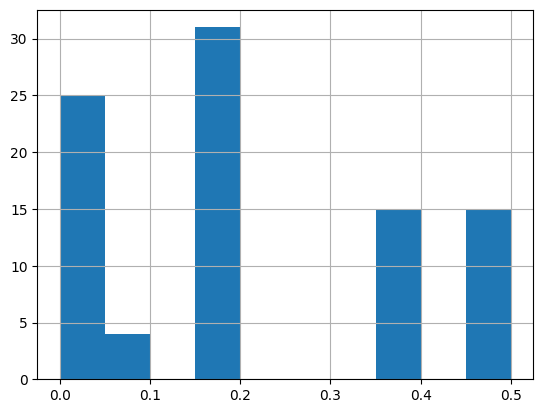

In [ ]:
pd.Series(probas).hist(), pd.Series(probas).describe()

# Redução de features

In [ ]:
# Importâncias
importancias = pd.Series(modelo_original.feature_importances_, index=X_train.columns)
importancias = importancias.sort_values(ascending=False)
importancias.head(15)


close_vs_adc_close_mean_geral            593.602402
adc_correl_com_principal_BEEF3           301.161100
dolar_trend                              168.918600
close_amplitude_norm_atr_principal        90.541520
adc_correl_com_principal_BRFS3            84.953588
macd_signal_mean                          59.739935
macd_signal_ultimo_norm_atr_principal     52.640001
adc_atr_pct_ultimo_BEEF3                  48.530800
tr_std                                    32.812199
ibov_trend                                23.509001
macd_ultimo_norm_atr_principal            22.926100
adc_rsi_ultimo_JBSS3                      22.244801
close_trend                               17.977699
adc_correl_com_principal_JBSS3            16.024582
correl_papel_ibov                         11.575900
dtype: float64

In [ ]:
import matplotlib.pyplot as plt
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score

def avaliar_precisao_recall_por_k_janelas(X_train, y_train, X_valid, y_valid, k_values, importancias, janela_treino=180, janela_teste=30):
    resultados_precisao = {}
    resultados_recall = {}

    for k in k_values:        
        colunas_selecionadas = importancias.head(k).index.tolist()        
        precisões = []
        recalls = []

        for i in range(0, len(X_valid) - janela_teste):
            X_val_teste = X_valid.iloc[i:i + janela_teste][colunas_selecionadas]
            y_val_teste = y_valid.iloc[i:i + janela_teste]

            #modelo = RandomForestClassifier(n_estimators=100, random_state=42)
            
            modelo, _ = criar_e_treinar_modelo_final_com_es_e_calib(
                X_train[colunas_selecionadas], y_train,
                fracao_eval_es=0.2, # Ex: 20% do super treino para ES e calibração prefit
                estrategia_calibracao_cv='prefit'
            )            

            y_pred = modelo.predict(X_val_teste)

            if (y_pred == 1).sum() > 0:
                # Se não houver predições positivas, não calcular precisão e recall
                
                prec = precision_score(y_val_teste, y_pred, zero_division=0)
                rec = recall_score(y_val_teste, y_pred, zero_division=0)

                precisões.append(prec)
                recalls.append(rec)

        resultados_precisao[k] = np.mean(precisões)
        resultados_recall[k] = np.mean(recalls)

    return resultados_precisao, resultados_recall

# Altere se quiser outro intervalo de k
k_values = list(range(5, min(51, X_train.shape[1] + 1), 5))
#k_values = [18, 20, 22, 25]
resultados_precisao, resultados_recall = avaliar_precisao_recall_por_k_janelas(X_train, y_train, X_validacao, y_validacao, k_values, importancias)

In [ ]:
resultados_precisao

{5: np.float64(nan),
 10: np.float64(nan),
 15: np.float64(nan),
 20: np.float64(nan),
 25: np.float64(0.0),
 30: np.float64(0.2811688311688311),
 35: np.float64(nan),
 40: np.float64(nan),
 45: np.float64(0.5968266852195424),
 50: np.float64(nan)}

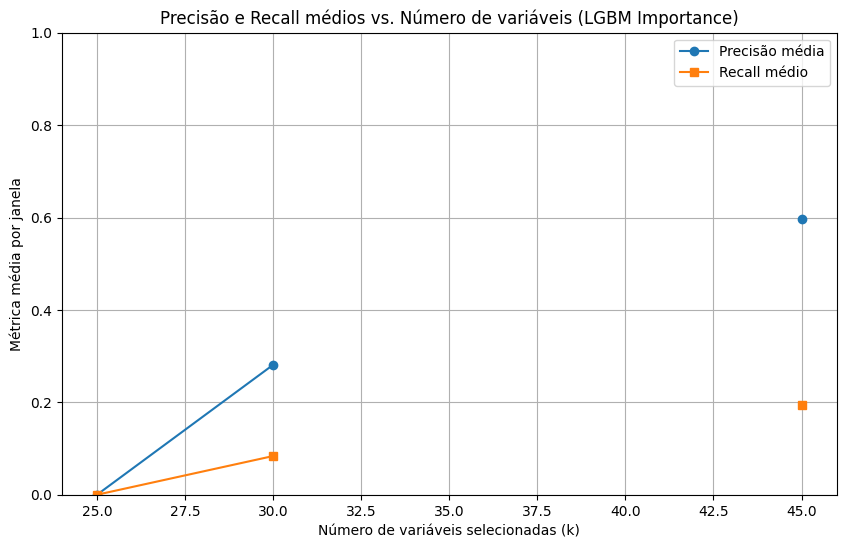

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(resultados_precisao.keys(), resultados_precisao.values(), marker='o', label='Precisão média')
plt.plot(resultados_recall.keys(), resultados_recall.values(), marker='s', label='Recall médio')
plt.title("Precisão e Recall médios vs. Número de variáveis (LGBM Importance)")
plt.xlabel("Número de variáveis selecionadas (k)")
plt.ylabel("Métrica média por janela")
plt.ylim(0, 1)
plt.legend()
plt.grid(True)
plt.show()

# Features reduzidas

In [ ]:
n_features = 55
lista_colunas_selecionadas = importancias.head(n_features).index.tolist()
lista_colunas_selecionadas

['close_vs_adc_close_mean_geral',
 'adc_correl_com_principal_BEEF3',
 'dolar_trend',
 'close_amplitude_norm_atr_principal',
 'adc_correl_com_principal_BRFS3',
 'macd_signal_mean',
 'macd_signal_ultimo_norm_atr_principal',
 'adc_atr_pct_ultimo_BEEF3',
 'tr_std',
 'ibov_trend',
 'macd_ultimo_norm_atr_principal',
 'adc_rsi_ultimo_JBSS3',
 'close_trend',
 'adc_correl_com_principal_JBSS3',
 'correl_papel_ibov',
 'retorno_desde_mudanca_close',
 'beta_papel_ibov',
 'macd_std',
 'macd_hist_std_norm_atr_principal',
 'ibov_std',
 'retorno_desde_mudanca_ibov',
 'volume_mean',
 'adc_rsi_ultimo_BEEF3',
 'retorno_desde_mudanca_dolar',
 'adc_macd_hist_ultimo_BRFS3',
 'rsi_std',
 'retorno_medio_pos',
 'close_amplitude',
 'close_min',
 'dias_queda_pct',
 'dias_alta_pct',
 'retorno_acumulado',
 'retorno_std',
 'retorno_mean',
 'mm5_vs_mm20',
 'close_vs_mm20',
 'close_ult_vs_mm_janela',
 'close_dist_min',
 'volume_ult_vs_mean',
 'rsi_ultimo',
 'macd_signal_std',
 'atr_pct_ultimo',
 'volume_trend',
 'volu

In [ ]:
X_train_reduzido = X_train[lista_colunas_selecionadas].copy()
X_validacao_reduzido = X_validacao[lista_colunas_selecionadas].copy()

In [ ]:
modelo_reduzido, _ = criar_e_treinar_modelo_final_com_es_e_calib(
    X_train_reduzido, y_train,
    fracao_eval_es=0.2, # Ex: 20% do super treino para ES e calibração prefit
    estrategia_calibracao_cv='prefit'    
)

#    Opção B: Calibrar com TimeSeriesSplit no conjunto de treino base do LGBM
#    (LGBM com n_estimators do ES é retreinado dentro dos folds do CalibratedCV)
#    tscv_para_calibracao = TimeSeriesSplit(n_splits=3)
#    modelo_treinado = criar_e_treinar_modelo_final_com_es_e_calib(
#        X_super_train_papel, y_super_train_papel,
#        fracao_eval_es=0.2, # Define o tamanho do eval_set_es, o resto é treino_base_lgbm
#        estrategia_calibracao_cv=tscv_para_calibracao
#    )
tr.comparar_auc_conjuntos(modelo_reduzido, X_train_reduzido, y_train, X_validacao_reduzido, y_validacao)

Dividindo Super Treino (485 amostras):
  - Treino Base LGBM: 388 amostras
  - Eval Set p/ Early Stopping (e possivelmente Calibração 'prefit'): 97 amostras

Iniciando treinamento LGBM com early stopping (monitorando 'auc')...
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[15]	valid_0's auc: 0.662662	valid_0's binary_logloss: 0.631605
Treinamento LGBM concluído. Melhor iteração: 15

Calibrando o LGBM treinado (método: isotonic)...
  Usando conjunto de early stopping (97 amostras) para treinar o calibrador (cv='prefit').
Calibração concluída.


c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with f

AUC no treino: 0.814
AUC na validação: 0.541
Diferença AUC (Treino - Validação): 0.274
PROVÁVEL OVERFITTING
PR AUC no treino: 0.505
PR AUC na validação: 0.428
Diferença PR AUC (Treino - Validação): 0.076
F1 Score no treino: 0.492
F1 Score na validação: 0.166


(np.float64(0.8141250496064021),
 np.float64(0.5406060128178298),
 np.float64(0.27351903678857226),
 np.float64(0.5045786748870741),
 np.float64(0.42818864226659953),
 np.float64(0.4923051803128624),
 np.float64(0.16609950196239195))

Avaliar e logar modelo
MLflow Run ID: b6c57f7fee6d4037bfafea7b5b8f712b para MRFG3.SA_6dias_x_0.07val_5dias_alvo
AUC no treino: 0.790
AUC na validação: 0.562

--- Conjunto de Treino --- Janelas

Threshold 0.50 - AUC: 0.814
  Precisão média (em 442 janelas com previsão positiva): 0.379
  Recall médio: 0.848

Calibrando thresholds para precisão mínima de 0.60...
Nenhum threshold atendeu à precisão mínima de 0.60. Seguindo com 0.5

Threshold ideal baseado em mínimo recall ou precisão: 0.50

--- Conjunto de Validação --- Janelas
Precisão média (em 52 janelas com previsão positiva): 0.437
Recall médio: 0.119
Sinais de compra presentes na vallidação: 27.0
Sinais de compra previstos na validação: 13
Modelo MRFG3.SA_6dias_x_0.07val_5dias_alvo salvo na run b6c57f7fee6d4037bfafea7b5b8f712b


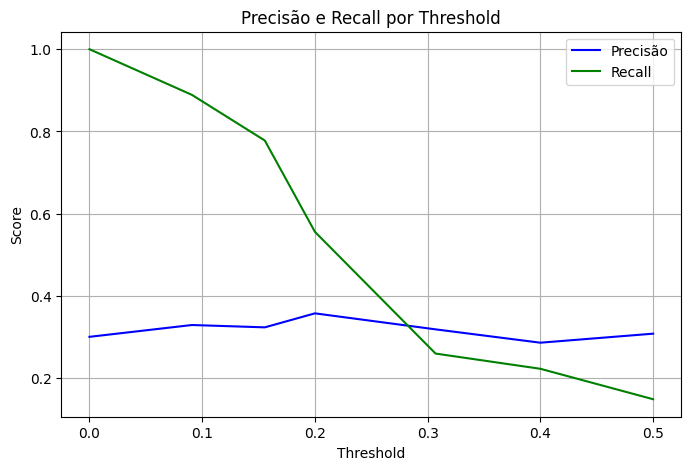

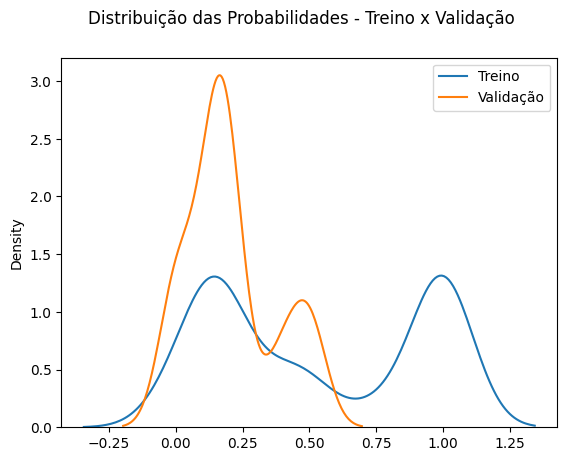

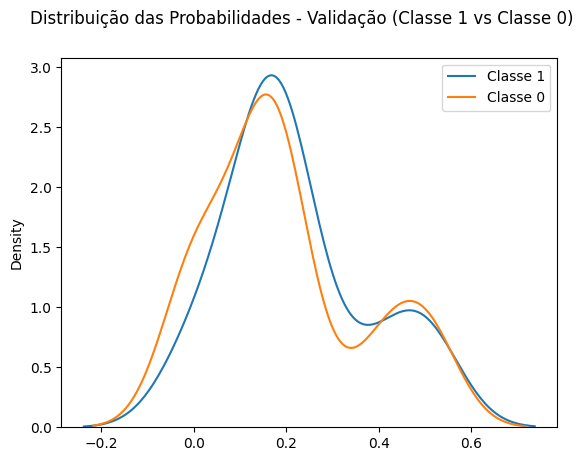

In [ ]:
precisao_minima = 0.6
recall_minimo = None
resultado = tr.avaliar_e_logar_modelo(modelo_reduzido, papel, X_train_reduzido, y_train, X_validacao_reduzido, y_validacao, dias_janela_x=DIAS_JANELA_X, valorizacao=valorizacao, dias_futuro_valorizacao=DIAS_FUTURO, dias_validacao=DIAS_VALIDACAO, recall_minimo=recall_minimo, precisao_minima=precisao_minima)
threshold_calibrado = resultado['threshold_calibrado']
probas = resultado['probas_validacao']
y_true = resultado['y_validacao']
y_pred = resultado['y_pred_validacao']

<Axes: >

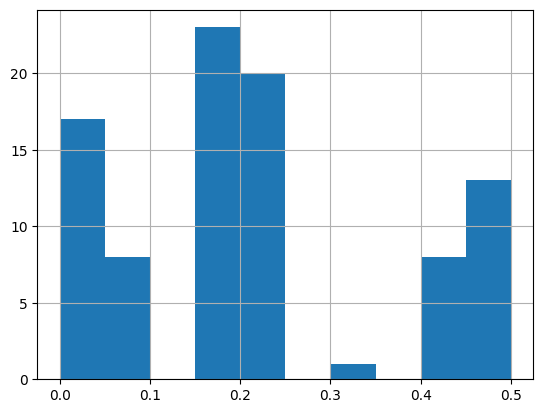

In [ ]:
pd.Series(probas).hist()

In [ ]:
pd.Series(probas).describe()

count    90.000000
mean      0.203468
std       0.161489
min       0.000000
25%       0.090909
50%       0.155556
75%       0.200000
max       0.500000
dtype: float64